In [2]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn as sns
import streamlit as st
import joblib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Streamlit:", st.__version__)

print("\nEnvironment setup successful!")

Python: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:27:36) [GCC 11.2.0]
NumPy: 2.5.4
Pandas: 2.2.3
Scikit-learn: 1.9.1
Matplotlib: 3.10.1
Seaborn: 0.13.2
Streamlit: 1.67.0

Environment setup successful!


In [4]:
# Step 1: Import the required libraries

import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# Step 2: Load the dataset

breast_cancer = load_breast_cancer(as_frame=True)

# Step 3: Convert it into a Pandas DataFrame

df = breast_cancer.frame.copy()

# Step 4: Display the first five records

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [6]:
print("Dataset shape:", df.shape)

print("Total instances:", df.shape[0])
print("Total columns:", df.shape[1])
print("Number of features:", df.shape[1] - 1)

Dataset shape: (569, 31)
Total instances: 569
Total columns: 31
Number of features: 30


In [8]:
print("Target names:", breast_cancer.target_names)

print("\nTarget distribution:")
print(df['target'].value_counts())

print("\nTarget labels:")
print(df['target'].value_counts().rename(index={
    0: 'Malignant',
    1: 'Benign'
}))

Target names: ['malignant' 'benign']

Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Target labels:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [10]:
print("All 30 input features:\n")

for i, column in enumerate(df.columns[:-1], start=1):
    print(f"{i}. {column}")

All 30 input features:

1. mean radius
2. mean texture
3. mean perimeter
4. mean area
5. mean smoothness
6. mean compactness
7. mean concavity
8. mean concave points
9. mean symmetry
10. mean fractal dimension
11. radius error
12. texture error
13. perimeter error
14. area error
15. smoothness error
16. compactness error
17. concavity error
18. concave points error
19. symmetry error
20. fractal dimension error
21. worst radius
22. worst texture
23. worst perimeter
24. worst area
25. worst smoothness
26. worst compactness
27. worst concavity
28. worst concave points
29. worst symmetry
30. worst fractal dimension


In [12]:
df.to_csv("breast_cancer_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [14]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [16]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:\n")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:

Series([], dtype: int64)

Total missing values: 0


In [18]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing value percentage:")
print(missing_percentage[missing_percentage > 0])

Missing value percentage:
Series([], dtype: float64)


In [20]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [22]:
duplicate_features = df.drop(columns=['target']).duplicated().sum()

print("Duplicate feature records:", duplicate_features)

Duplicate feature records: 0


In [24]:
print(df.dtypes)

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [26]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=np.number).columns

print("Number of numerical columns:", len(numerical_columns))
print("Numerical columns:", list(numerical_columns))

Number of numerical columns: 31
Numerical columns: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']


In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


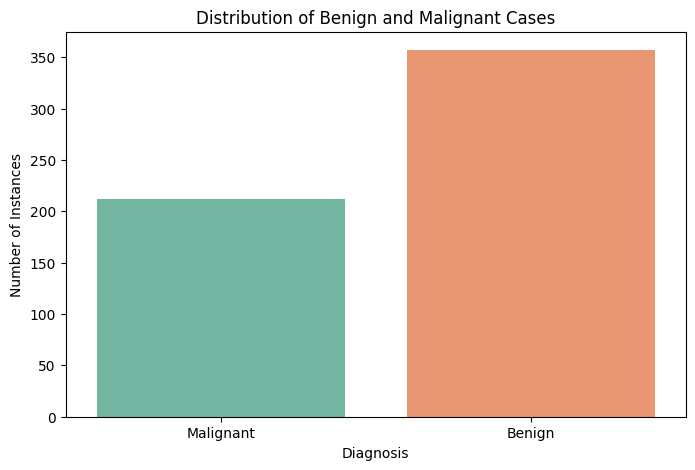

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='target',
    hue='target',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Instances")

plt.xticks(
    ticks=[0, 1],
    labels=['Malignant', 'Benign']
)

plt.show()

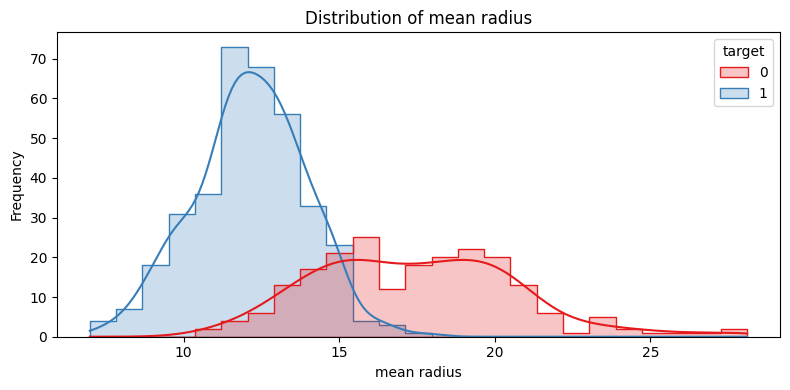

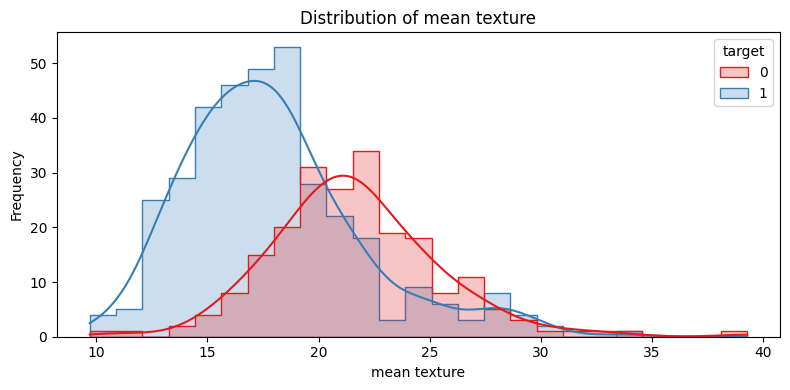

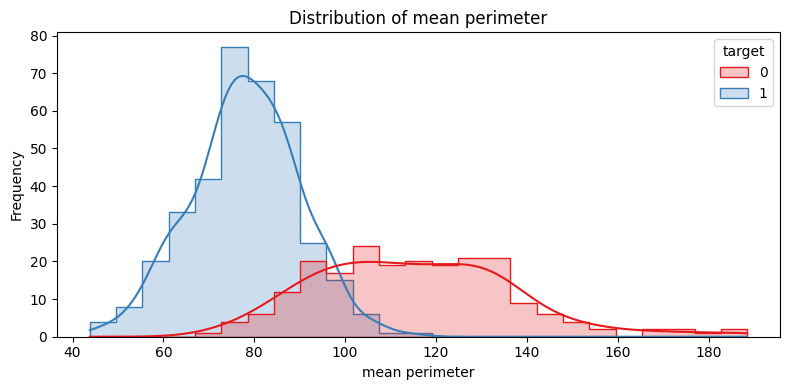

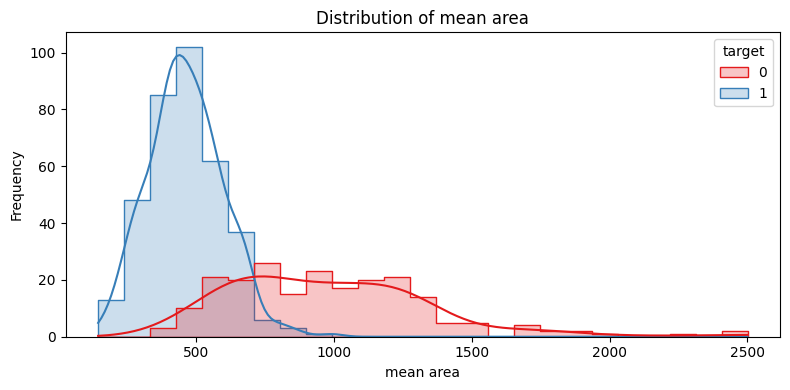

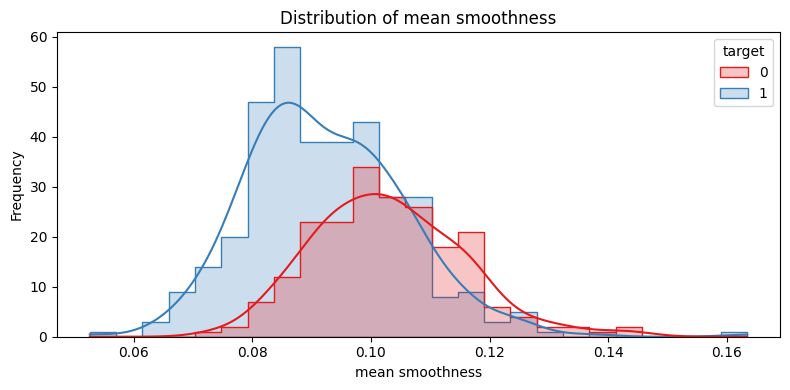

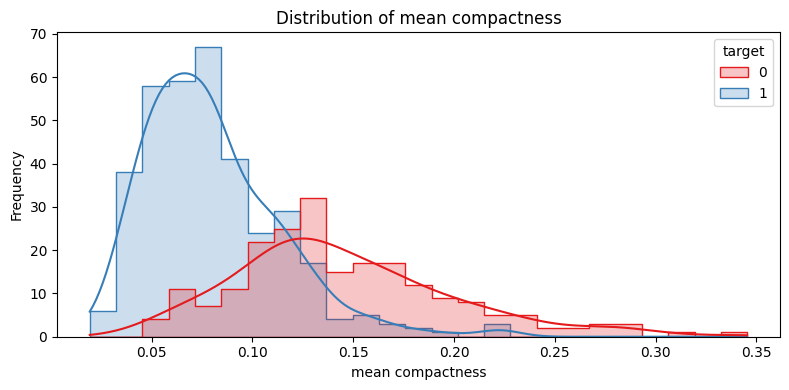

In [32]:
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean compactness'
]

for feature in selected_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue='target',
        bins=25,
        kde=True,
        palette='Set1',
        element='step'
    )

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

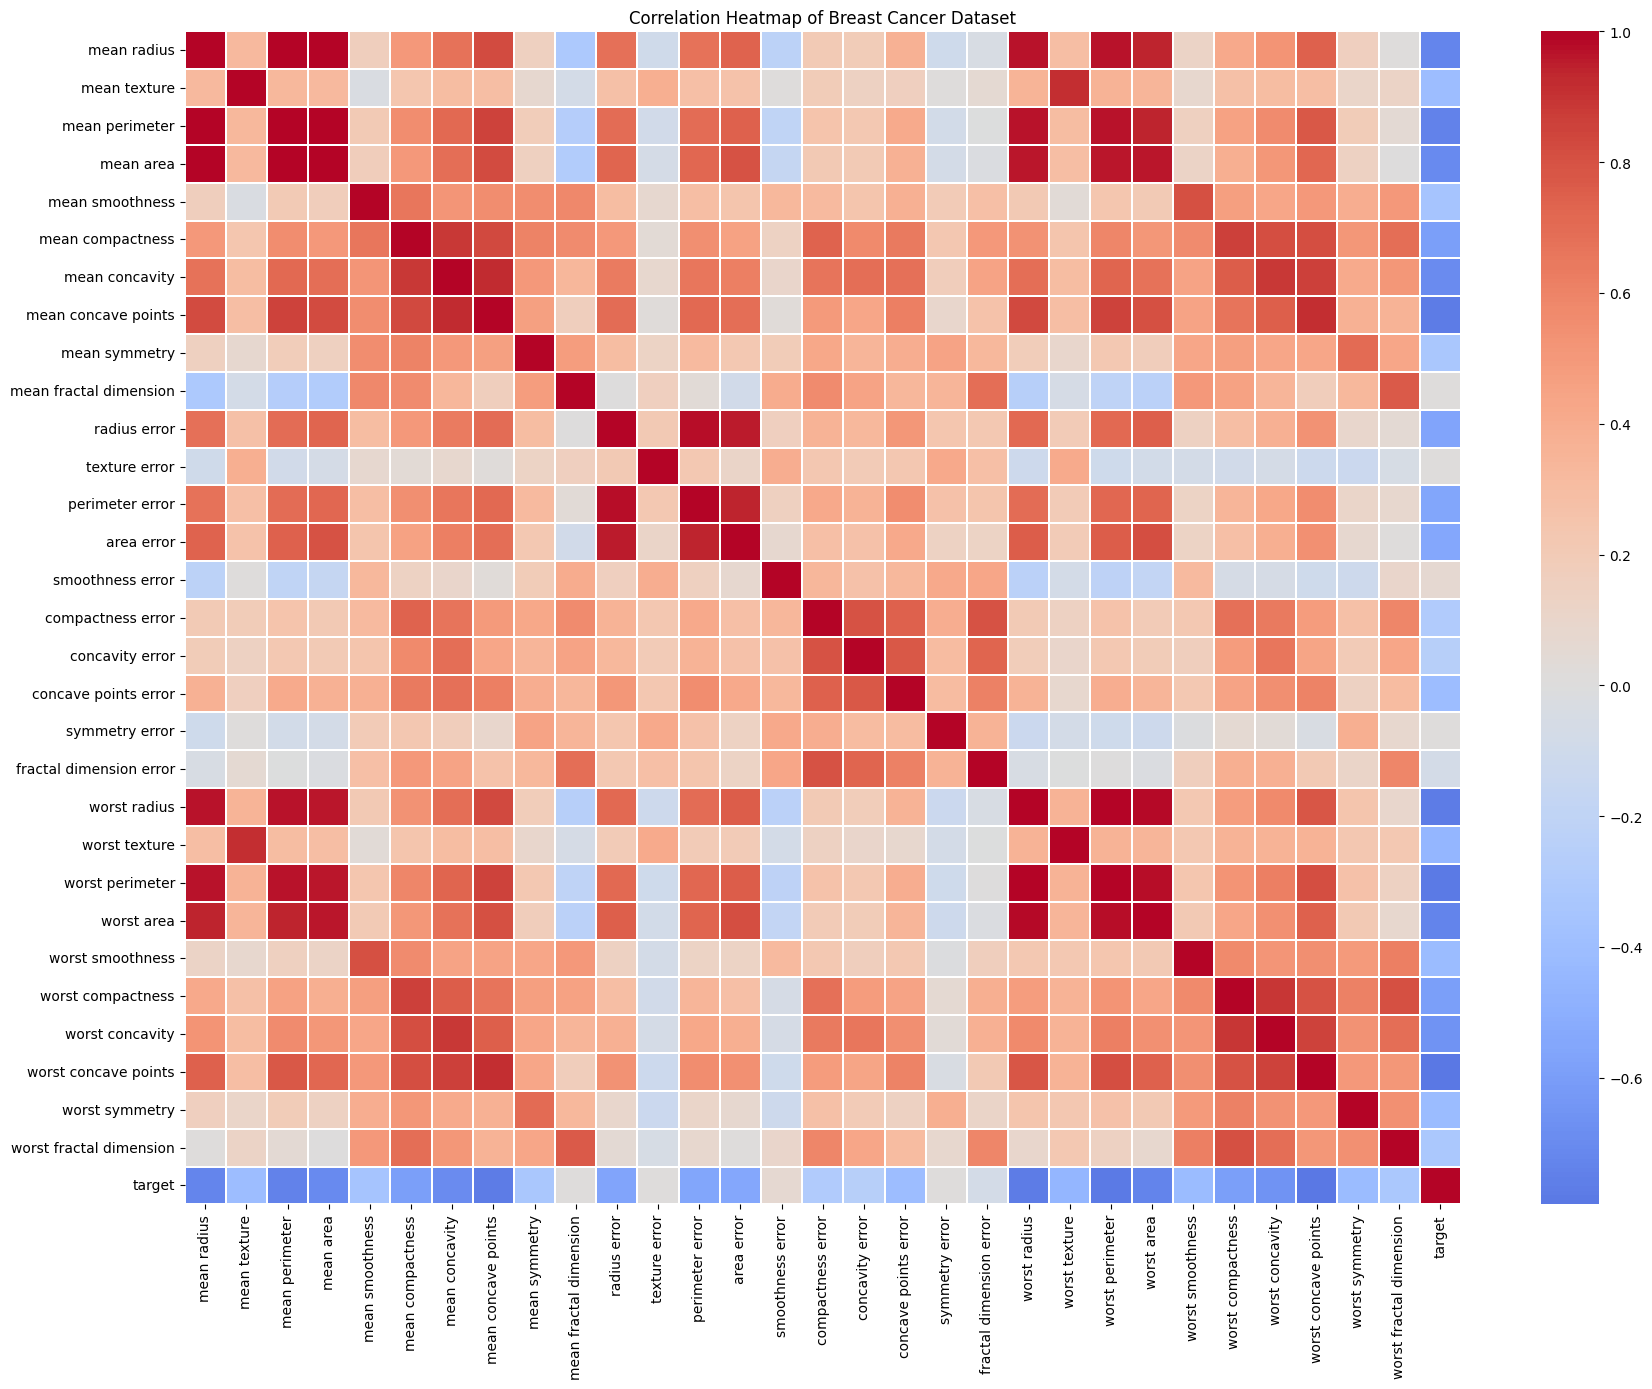

In [34]:
# Calculate correlation matrix

correlation_matrix = df.corr()

# Display correlation heatmap

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Breast Cancer Dataset")

plt.tight_layout()
plt.show()

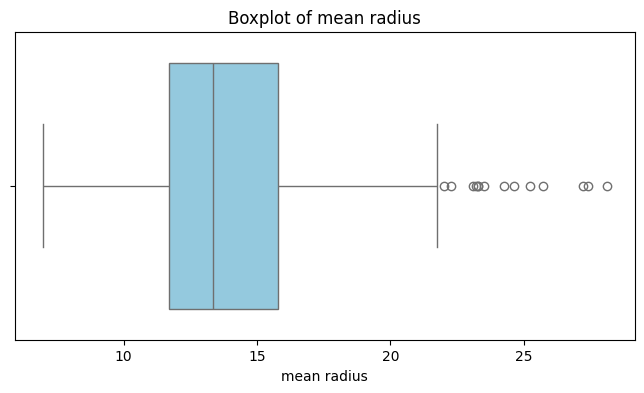

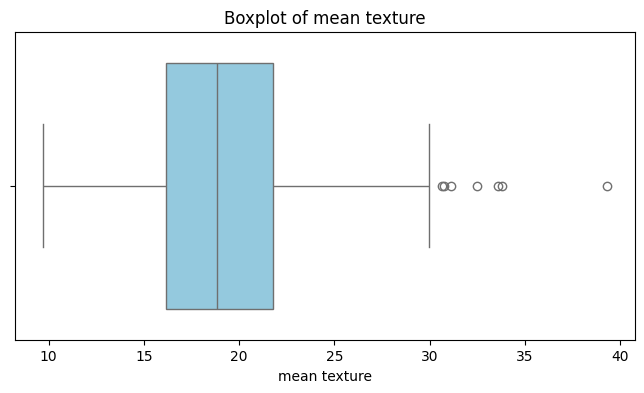

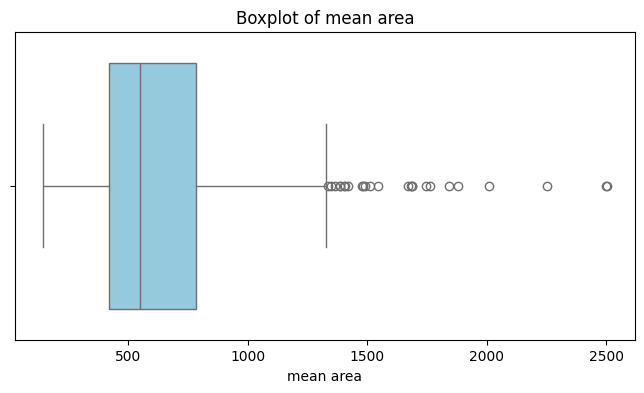

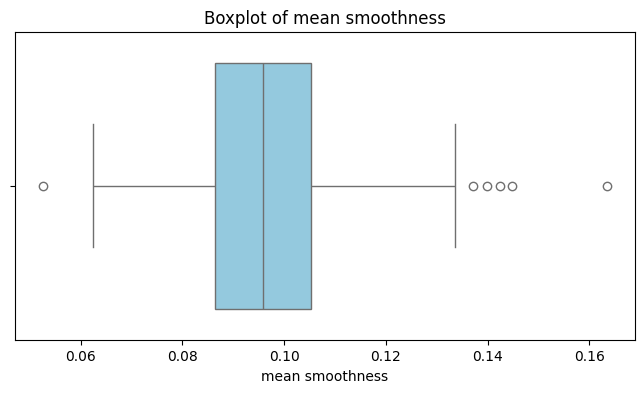

In [36]:
outlier_features = [
    'mean radius',
    'mean texture',
    'mean area',
    'mean smoothness'
]

for feature in outlier_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[feature],
        color='skyblue'
    )

    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)

    plt.show()

In [38]:
data_quality_summary = pd.DataFrame({
    'Check': [
        'Total Records',
        'Total Features',
        'Missing Values',
        'Duplicate Records',
        'Duplicate Feature Records'
    ],
    'Result': [
        df.shape[0],
        df.shape[1] - 1,
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df.drop(columns=['target']).duplicated().sum()
    ]
})

data_quality_summary

,Check,Result
0,Total Records,569
1,Total Features,30
2,Missing Values,0
3,Duplicate Records,0
4,Duplicate Feature Records,0


In [40]:
# Separate input features and target variable

X = df.drop(columns=['target'])

y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five feature records:")
display(X.head())

print("\nFirst five target values:")
display(y.head())

Features shape: (569, 30)
Target shape: (569,)

First five feature records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



First five target values:


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [42]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)


In [44]:
print("Original dataset distribution:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining dataset distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting dataset distribution:")
print(y_test.value_counts(normalize=True) * 100)

Original dataset distribution:
target
1    62.741652
0    37.258348
Name: proportion, dtype: float64

Training dataset distribution:
target
1    62.637363
0    37.362637
Name: proportion, dtype: float64

Testing dataset distribution:
target
1    63.157895
0    36.842105
Name: proportion, dtype: float64


In [46]:
from sklearn.preprocessing import StandardScaler

# Create the scaler

scaler = StandardScaler()

# Fit scaler on training data and transform it

X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler

X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("Original testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Original training shape: (455, 30)
Scaled training shape: (455, 30)
Original testing shape: (114, 30)
Scaled testing shape: (114, 30)


In [48]:
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("Mean of first five scaled features:")
print(scaled_df.mean().head())

print("\nStandard deviation of first five scaled features:")
print(scaled_df.std().head())

Mean of first five scaled features:
mean radius       -2.928061e-16
mean texture       6.246530e-16
mean perimeter    -1.629954e-16
mean area         -1.717796e-16
mean smoothness    6.246530e-17
dtype: float64

Standard deviation of first five scaled features:
mean radius        1.001101
mean texture       1.001101
mean perimeter     1.001101
mean area          1.001101
mean smoothness    1.001101
dtype: float64


In [50]:
import joblib

# Save the scaler

joblib.dump(scaler, "scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [52]:
# Import classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Import model saving utility
import joblib
import os

print("All five classification algorithms imported successfully!")

All five classification algorithms imported successfully!


In [54]:
# Create Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

# Train the model

logistic_model.fit(X_train_scaled, y_train)

# Generate predictions

logistic_predictions = logistic_model.predict(X_test_scaled)

print("Logistic Regression training completed!")
print("Number of predictions:", len(logistic_predictions))

print("\nFirst 10 predictions:")
print(logistic_predictions[:10])

Logistic Regression training completed!
Number of predictions: 114

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


In [56]:
# Create Decision Tree model

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model

decision_tree_model.fit(X_train, y_train)

# Generate predictions

decision_tree_predictions = decision_tree_model.predict(X_test)

print("Decision Tree training completed!")
print("Number of predictions:", len(decision_tree_predictions))

print("\nFirst 10 predictions:")
print(decision_tree_predictions[:10])

Decision Tree training completed!
Number of predictions: 114

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


In [58]:
# Create KNN model

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

# Train the model

knn_model.fit(X_train_scaled, y_train)

# Generate predictions

knn_predictions = knn_model.predict(X_test_scaled)

print("KNN training completed!")
print("Number of predictions:", len(knn_predictions))

print("\nFirst 10 predictions:")
print(knn_predictions[:10])

KNN training completed!
Number of predictions: 114

First 10 predictions:
[0 1 0 0 0 1 1 0 0 0]


In [60]:
# Create Gaussian Naive Bayes model

naive_bayes_model = GaussianNB()

# Train the model

naive_bayes_model.fit(X_train, y_train)

# Generate predictions

naive_bayes_predictions = naive_bayes_model.predict(X_test)

print("Gaussian Naive Bayes training completed!")
print("Number of predictions:", len(naive_bayes_predictions))

print("\nFirst 10 predictions:")
print(naive_bayes_predictions[:10])

Gaussian Naive Bayes training completed!
Number of predictions: 114

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


In [62]:
# Create SVM model

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

# Train the model

svm_model.fit(X_train_scaled, y_train)

# Generate predictions

svm_predictions = svm_model.predict(X_test_scaled)

print("SVM training completed!")
print("Number of predictions:", len(svm_predictions))

print("\nFirst 10 predictions:")
print(svm_predictions[:10])

SVM training completed!
Number of predictions: 114

First 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [64]:
# Collect all model predictions

model_predictions = {
    'Logistic Regression': logistic_predictions,
    'Decision Tree': decision_tree_predictions,
    'KNN': knn_predictions,
    'Naive Bayes': naive_bayes_predictions,
    'Support Vector Machine': svm_predictions
}

# Display prediction counts

for model_name, predictions in model_predictions.items():

    print(model_name)
    print("Total predictions:", len(predictions))
    print("Predicted classes:", np.unique(predictions))
    print("-" * 40)

Logistic Regression
Total predictions: 114
Predicted classes: [0 1]
----------------------------------------
Decision Tree
Total predictions: 114
Predicted classes: [0 1]
----------------------------------------
KNN
Total predictions: 114
Predicted classes: [0 1]
----------------------------------------
Naive Bayes
Total predictions: 114
Predicted classes: [0 1]
----------------------------------------
Support Vector Machine
Total predictions: 114
Predicted classes: [0 1]
----------------------------------------


In [66]:
# Create models directory

os.makedirs("models", exist_ok=True)

# Save all trained models

joblib.dump(logistic_model, "models/logistic_regression.pkl")

joblib.dump(decision_tree_model, "models/decision_tree.pkl")

joblib.dump(knn_model, "models/knn.pkl")

joblib.dump(naive_bayes_model, "models/naive_bayes.pkl")

joblib.dump(svm_model, "models/svm.pkl")

# Save preprocessing scaler

joblib.dump(scaler, "models/scaler.pkl")

print("All five models and scaler saved successfully!")

All five models and scaler saved successfully!


In [68]:
# Check saved files

print("Saved model files:\n")

for file in os.listdir("models"):
    file_path = os.path.join("models", file)

    print(
        file,
        "-",
        round(os.path.getsize(file_path) / 1024, 2),
        "KB"
    )

Saved model files:

logistic_regression.pkl - 1.08 KB
decision_tree.pkl - 5.1 KB
knn.pkl - 110.99 KB
naive_bayes.pkl - 2.63 KB
svm.pkl - 26.28 KB
scaler.pkl - 2.21 KB


In [70]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("All evaluation metrics imported successfully!")

All evaluation metrics imported successfully!


In [72]:
# Store models and their corresponding test data

models = {
    'Logistic Regression': {
        'model': logistic_model,
        'X_test': X_test_scaled
    },

    'Decision Tree': {
        'model': decision_tree_model,
        'X_test': X_test
    },

    'KNN': {
        'model': knn_model,
        'X_test': X_test_scaled
    },

    'Naive Bayes': {
        'model': naive_bayes_model,
        'X_test': X_test
    },

    'Support Vector Machine': {
        'model': svm_model,
        'X_test': X_test_scaled
    }
}

print("All five models organized successfully!")

All five models organized successfully!


In [74]:
# Dictionary to store evaluation results

evaluation_results = []

# Dictionary to store confusion matrices

confusion_matrices = {}

# Dictionary to store classification reports

classification_reports = {}

# Evaluate each model

for model_name, model_info in models.items():

    model = model_info['model']
    test_features = model_info['X_test']

    # Generate predicted classes
    y_pred = model.predict(test_features)

    # Generate probability scores for the Benign class (1)
    y_prob = model.predict_proba(test_features)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(y_test, y_prob)

    precision = precision_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=1, zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store metrics
    evaluation_results.append({
        'ML Model Name': model_name,
        'Accuracy': accuracy,
        'AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'MCC': mcc
    })

    # Store confusion matrix
    confusion_matrices[model_name] = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    # Store classification report
    classification_reports[model_name] = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Malignant', 'Benign'],
        zero_division=0
    )

print("Evaluation of all five models completed!")

Evaluation of all five models completed!


In [76]:
# Convert evaluation results into a DataFrame

results_df = pd.DataFrame(evaluation_results)

# Round metric values to four decimal places

results_df = results_df.round(4)

# Display comparison table

display(results_df)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


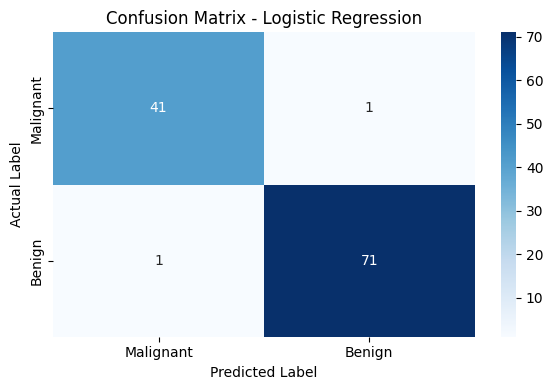

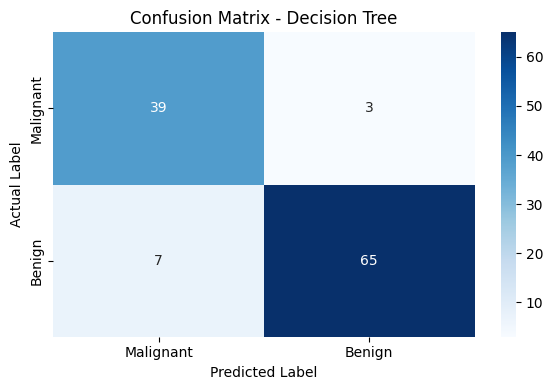

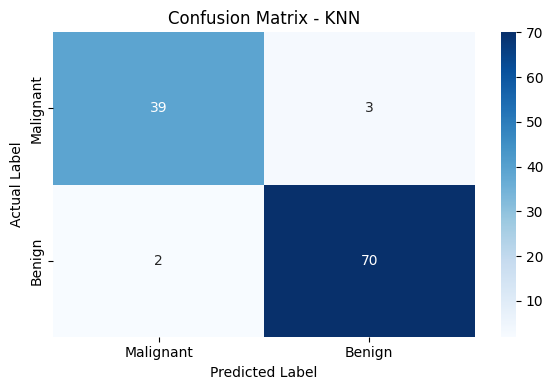

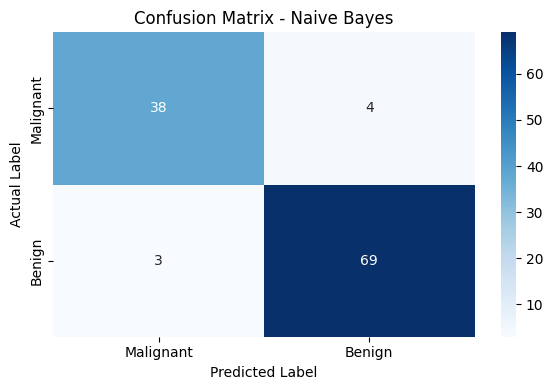

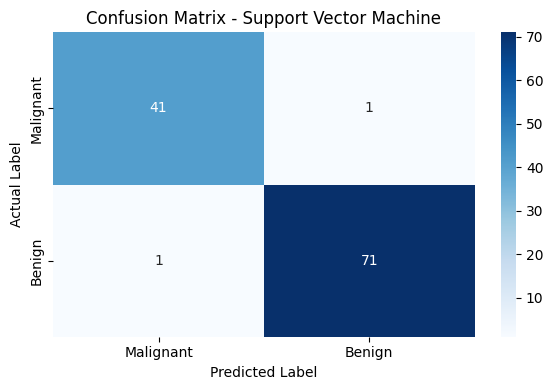

In [78]:
for model_name, cm in confusion_matrices.items():

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Malignant', 'Benign'],
        yticklabels=['Malignant', 'Benign']
    )

    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')

    plt.tight_layout()
    plt.show()

In [80]:
for model_name, report in classification_reports.items():

    print("=" * 65)
    print("Classification Report:", model_name)
    print("=" * 65)

    print(report)

Classification Report: Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Classification Report: Decision Tree
              precision    recall  f1-score   support

   Malignant       0.85      0.93      0.89        42
      Benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

Classification Report: KNN
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.

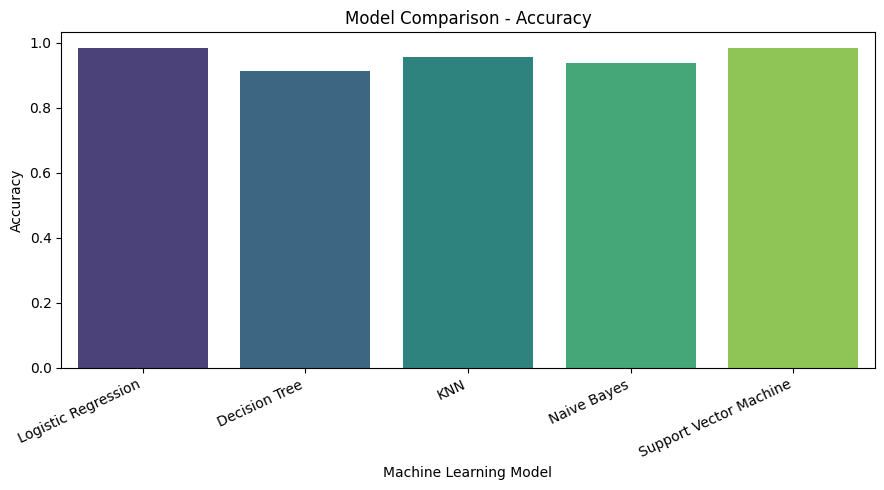

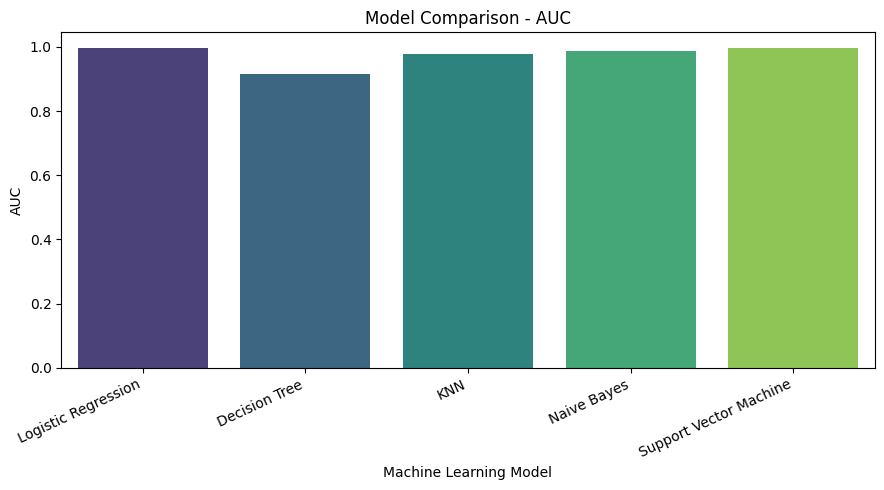

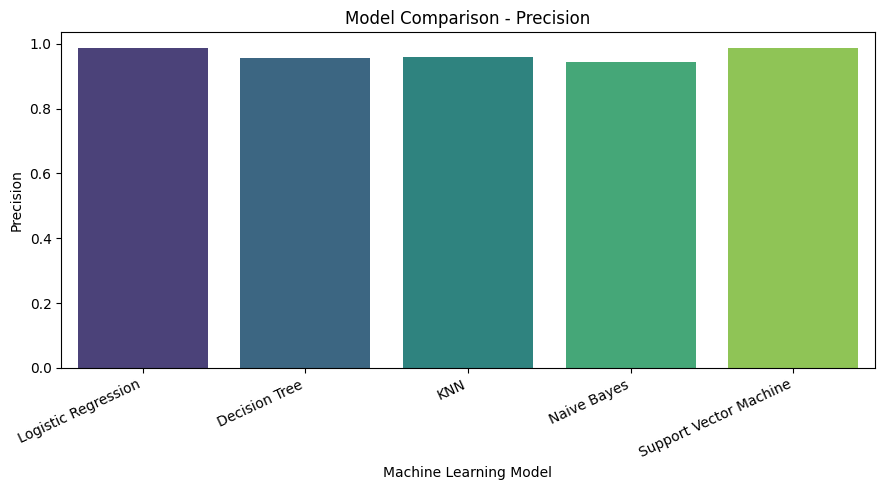

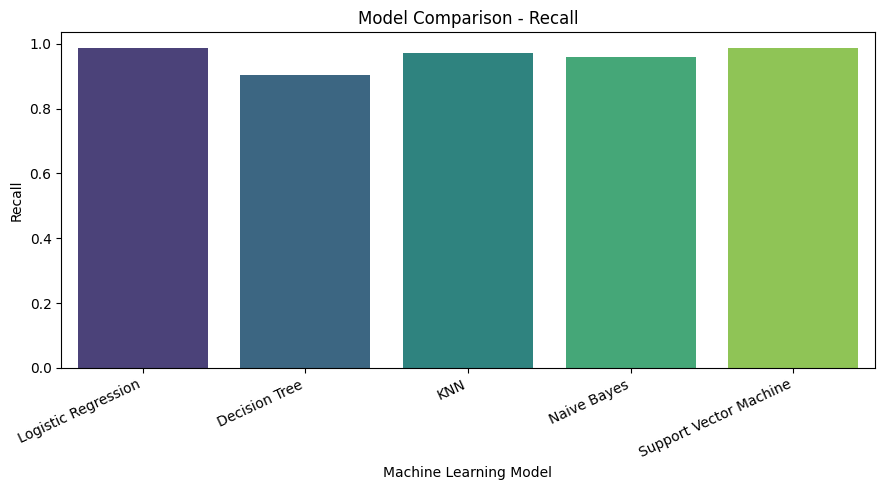

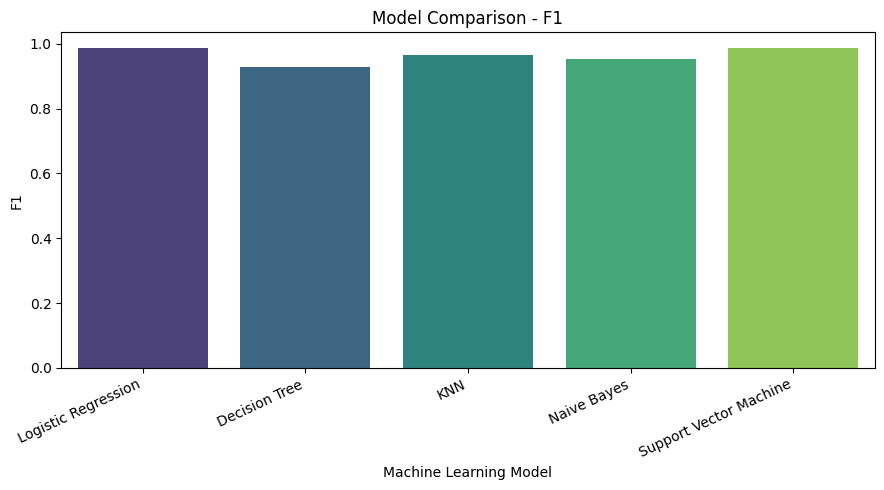

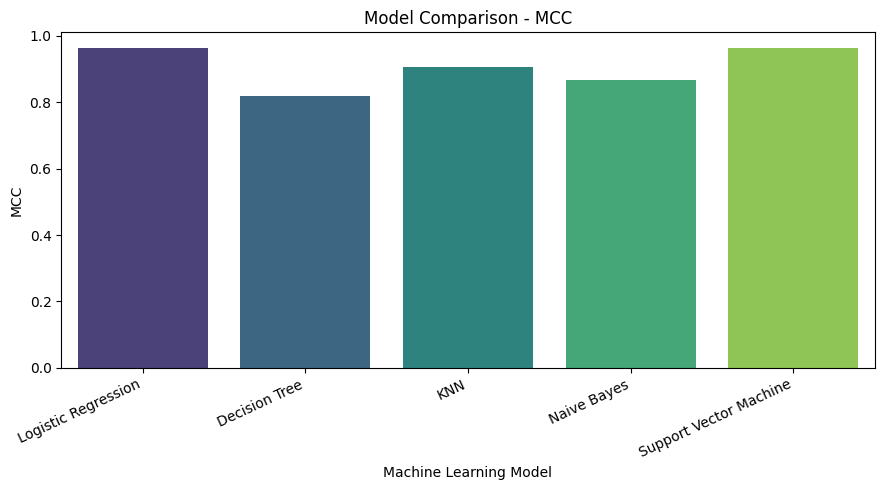

In [82]:
# Plot comparison of evaluation metrics

metrics = [
    'Accuracy',
    'AUC',
    'Precision',
    'Recall',
    'F1',
    'MCC'
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x='ML Model Name',
        y=metric,
        hue='ML Model Name',
        palette='viridis',
        legend=False
    )

    plt.title(f'Model Comparison - {metric}')
    plt.xlabel('Machine Learning Model')
    plt.ylabel(metric)

    plt.xticks(rotation=25, ha='right')

    plt.tight_layout()
    plt.show()

In [84]:
# Save comparison table

results_df.to_csv(
    'model_evaluation_results.csv',
    index=False
)

# Save confusion matrices

for model_name, cm in confusion_matrices.items():

    filename = (
        model_name.lower()
        .replace(' ', '_')
        + '_confusion_matrix.csv'
    )

    pd.DataFrame(
        cm,
        index=['Actual_Malignant', 'Actual_Benign'],
        columns=['Predicted_Malignant', 'Predicted_Benign']
    ).to_csv(filename)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [86]:
class_analysis = []

for model_name, cm in confusion_matrices.items():

    # Confusion matrix layout:
    #                 Predicted
    #                 Malignant  Benign
    # Actual Malignant    cm[0,0]  cm[0,1]
    #        Benign       cm[1,0]  cm[1,1]

    malignant_recall = cm[0, 0] / cm[0, :].sum()
    benign_recall = cm[1, 1] / cm[1, :].sum()

    malignant_false_negatives = cm[0, 1]

    class_analysis.append({
        'ML Model Name': model_name,
        'Malignant Recall': malignant_recall,
        'Benign Recall': benign_recall,
        'Malignant False Negatives': malignant_false_negatives
    })

class_analysis_df = pd.DataFrame(class_analysis).round(4)

display(class_analysis_df)

,ML Model Name,Malignant Recall,Benign Recall,Malignant False Negatives
0,Logistic Regression,0.9762,0.9861,1
1,Decision Tree,0.9286,0.9028,3
2,KNN,0.9286,0.9722,3
3,Naive Bayes,0.9048,0.9583,4
4,Support Vector Machine,0.9762,0.9861,1


In [88]:
final_comparison = results_df.merge(
    class_analysis_df,
    on='ML Model Name'
)

display(final_comparison)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Malignant Recall,Benign Recall,Malignant False Negatives
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623,0.9762,0.9861,1
1,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174,0.9286,0.9028,3
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054,0.9286,0.9722,3
3,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676,0.9048,0.9583,4
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623,0.9762,0.9861,1


In [90]:
ranked_models = final_comparison.sort_values(
    by='MCC',
    ascending=False
).reset_index(drop=True)

ranked_models.insert(
    0,
    'Rank',
    range(1, len(ranked_models) + 1)
)

display(ranked_models)

,Rank,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Malignant Recall,Benign Recall,Malignant False Negatives
0,1,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623,0.9762,0.9861,1
1,2,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623,0.9762,0.9861,1
2,3,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054,0.9286,0.9722,3
3,4,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676,0.9048,0.9583,4
4,5,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174,0.9286,0.9028,3


In [92]:
best_mcc_model = ranked_models.iloc[0]

print("PRELIMINARY BEST MODEL BASED ON MCC")
print("-----------------------------------")
print("Model:", best_mcc_model['ML Model Name'])
print("MCC:", best_mcc_model['MCC'])
print("Accuracy:", best_mcc_model['Accuracy'])
print("AUC:", best_mcc_model['AUC'])
print("F1 Score:", best_mcc_model['F1'])
print("Malignant Recall:", best_mcc_model['Malignant Recall'])
print("Malignant False Negatives:",
      best_mcc_model['Malignant False Negatives'])

PRELIMINARY BEST MODEL BASED ON MCC
-----------------------------------
Model: Logistic Regression
MCC: 0.9623
Accuracy: 0.9825
AUC: 0.9954
F1 Score: 0.9861
Malignant Recall: 0.9762
Malignant False Negatives: 1


In [94]:
final_comparison.to_csv(
    'final_model_comparison.csv',
    index=False
)

print("Final model comparison saved successfully.")

Final model comparison saved successfully.


In [96]:
from sklearn.metrics import recall_score

final_comparison = []

for model_name, model_info in models.items():

    model = model_info['model']
    test_features = model_info['X_test']

    predictions = model.predict(test_features)

    cm = confusion_matrices[model_name]

    # Malignant is class 0
    malignant_recall = recall_score(
        y_test,
        predictions,
        pos_label=0,
        zero_division=0
    )

    # Actual malignant predicted as benign
    malignant_false_negatives = cm[0, 1]

    final_comparison.append({
        'ML Model Name': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'AUC': roc_auc_score(
            y_test,
            model.predict_proba(test_features)[:, 1]
        ),
        'Precision': precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        'F1': f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        'MCC': matthews_corrcoef(y_test, predictions),
        'Malignant Recall': malignant_recall,
        'Malignant False Negatives': malignant_false_negatives
    })

final_comparison_df = pd.DataFrame(final_comparison)

display(final_comparison_df.round(4))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Malignant Recall,Malignant False Negatives
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623,0.9762,1
1,Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174,0.9286,3
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054,0.9286,3
3,Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676,0.9048,4
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623,0.9762,1


In [98]:
print("MODEL RANKING BASED ON MCC")
print("=" * 60)

ranking = final_comparison_df.sort_values(
    by=['MCC', 'AUC', 'Malignant Recall'],
    ascending=False
)

display(ranking.round(6))

best_model_name = ranking.iloc[0]['ML Model Name']

print("\nPRELIMINARY BEST MODEL")
print("=" * 60)
print("Model:", best_model_name)
print("MCC:", round(ranking.iloc[0]['MCC'], 6))
print("Accuracy:", round(ranking.iloc[0]['Accuracy'], 6))
print("AUC:", round(ranking.iloc[0]['AUC'], 6))
print("F1:", round(ranking.iloc[0]['F1'], 6))
print("Malignant Recall:", round(
    ranking.iloc[0]['Malignant Recall'], 6
))
print("Malignant False Negatives:",
      int(ranking.iloc[0]['Malignant False Negatives']))

MODEL RANKING BASED ON MCC


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Malignant Recall,Malignant False Negatives
0,Logistic Regression,0.982456,0.995370,0.986111,0.986111,0.986111,0.962302,0.976190,1
4,Support Vector Machine,0.982456,0.995040,0.986111,0.986111,0.986111,0.962302,0.976190,1
2,KNN,0.956140,0.978836,0.958904,0.972222,0.965517,0.905447,0.928571,3
3,Naive Bayes,0.938596,0.987765,0.945205,0.958333,0.951724,0.867553,0.904762,4
1,Decision Tree,0.912281,0.915675,0.955882,0.902778,0.928571,0.817412,0.928571,3



PRELIMINARY BEST MODEL
Model: Logistic Regression
MCC: 0.962302
Accuracy: 0.982456
AUC: 0.99537
F1: 0.986111
Malignant Recall: 0.97619
Malignant False Negatives: 1


In [100]:
final_comparison_df.to_csv(
    'final_model_comparison.csv',
    index=False
)

print("Final comparison table saved successfully!")

Final comparison table saved successfully!


In [102]:
# Create test dataset containing features and actual target labels

test_data = X_test.copy()

test_data['target'] = y_test.values

# Save the test dataset
test_data.to_csv('test_data.csv', index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully!
Test dataset shape: (114, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
256,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,...,36.27,178.60,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,0
428,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,1
501,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,...,32.94,106.00,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,0
363,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,...,25.45,117.20,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,1
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,0


In [104]:
import sklearn
import streamlit
import numpy
import pandas
import joblib

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Streamlit:", streamlit.__version__)
print("Joblib:", joblib.__version__)

NumPy: 2.5.4
Pandas: 2.2.3
Scikit-learn: 1.9.1
Streamlit: 1.67.0
Joblib: 1.4.2


In [106]:
import sklearn
import streamlit
import numpy
import pandas
import joblib
import matplotlib

print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
print("streamlit:", streamlit.__version__)
print("joblib:", joblib.__version__)
print("matplotlib:", matplotlib.__version__)

numpy: 2.5.4
pandas: 2.2.3
scikit-learn: 1.9.1
streamlit: 1.67.0
joblib: 1.4.2
matplotlib: 3.10.1


In [108]:
from pathlib import Path

gitignore_content = """__pycache__/
.ipynb_checkpoints/
.venv/
venv/
env/
*.pyc
.DS_Store
"""

Path(".gitignore").write_text(gitignore_content)

print(".gitignore created successfully!")

.gitignore created successfully!


In [110]:
import os

print(".gitignore exists:", os.path.exists(".gitignore"))

print("\nFile content:")
with open(".gitignore", "r") as file:
    print(file.read())

.gitignore exists: True

File content:
__pycache__/
.ipynb_checkpoints/
.venv/
venv/
env/
*.pyc
.DS_Store

